In [ ]:
# ================================================================
# TAHAP 1
# IMPORT LIBRARY DAN FUNGSI DASAR
# ================================================================

import os
import io
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

from IPython.display import display
from google.colab import files


def judul(teks):
    print("\n" + "=" * 78)
    print(teks)
    print("=" * 78)


def konversi_angka(nilai):
    """
    Mengubah nilai seperti:
    Rp 1.500.000 | 1.500.000,50 | 1,500,000.50 | 75,5 | 80%
    menjadi float.
    """

    if pd.isna(nilai):
        return np.nan

    if isinstance(nilai, (int, float, np.integer, np.floating)):
        return float(nilai)

    teks = str(nilai).strip()

    if teks.lower() in ["", "nan", "none", "null", "-"]:
        return np.nan

    teks = teks.replace("Rp", "")
    teks = teks.replace("rp", "")
    teks = teks.replace("%", "")
    teks = teks.replace(" ", "")

    # Format yang memiliki titik dan koma
    if "." in teks and "," in teks:

        # Contoh: 1.500.000,50
        if teks.rfind(",") > teks.rfind("."):
            teks = teks.replace(".", "")
            teks = teks.replace(",", ".")

        # Contoh: 1,500,000.50
        else:
            teks = teks.replace(",", "")

    # Format yang hanya memiliki koma
    elif "," in teks:
        bagian = teks.split(",")

        # Contoh: 75,5
        if len(bagian) == 2 and len(bagian[-1]) <= 2:
            teks = teks.replace(",", ".")

        # Contoh: 1,500 atau 1,500,000
        else:
            teks = teks.replace(",", "")

    # Contoh: 1.500.000
    elif teks.count(".") > 1:
        teks = teks.replace(".", "")

    # Contoh: 1.500 dianggap 1500
    elif teks.count(".") == 1:
        sebelum, sesudah = teks.split(".")

        if (
            len(sesudah) == 3
            and sebelum.replace("-", "").isdigit()
            and sesudah.isdigit()
        ):
            teks = sebelum + sesudah

    try:
        return float(teks)

    except ValueError:
        return np.nan


print("Tahap 1 berhasil dijalankan.")
print("Library dan fungsi dasar sudah tersedia.")

Tahap 1 berhasil dijalankan.
Library dan fungsi dasar sudah tersedia.


In [ ]:
# ================================================================
# TAHAP 2
# UPLOAD DAN MEMBACA DATASET
# ================================================================

judul("TAHAP 2 - UPLOAD DATA ALTERNATIF")

print("Unggah satu file CSV, XLSX, atau XLS.")
uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Tidak ada file yang diunggah.")

nama_file_input = list(uploaded.keys())[0]
isi_file = uploaded[nama_file_input]
ekstensi = os.path.splitext(nama_file_input)[1].lower()

if ekstensi == ".csv":

    try:
        df_asli = pd.read_csv(
            io.BytesIO(isi_file),
            sep=None,
            engine="python"
        )

    except UnicodeDecodeError:
        df_asli = pd.read_csv(
            io.BytesIO(isi_file),
            sep=None,
            engine="python",
            encoding="latin-1"
        )

elif ekstensi in [".xlsx", ".xls"]:

    file_excel = pd.ExcelFile(io.BytesIO(isi_file))

    print("\nDaftar sheet:")

    for nomor, nama_sheet in enumerate(file_excel.sheet_names, start=1):
        print(f"{nomor}. {nama_sheet}")

    if len(file_excel.sheet_names) == 1:
        sheet_dipilih = file_excel.sheet_names[0]

    else:
        while True:
            pilihan_sheet = input("\nMasukkan nomor sheet: ").strip()

            if pilihan_sheet.isdigit():
                nomor_sheet = int(pilihan_sheet)

                if 1 <= nomor_sheet <= len(file_excel.sheet_names):
                    sheet_dipilih = file_excel.sheet_names[nomor_sheet - 1]
                    break

            print("Nomor sheet tidak valid.")

    df_asli = pd.read_excel(
        io.BytesIO(isi_file),
        sheet_name=sheet_dipilih
    )

else:
    raise ValueError(
        "Format file tidak didukung. Gunakan CSV, XLSX, atau XLS."
    )

# Membersihkan nama kolom
df_asli.columns = [str(kolom).strip() for kolom in df_asli.columns]

# Menghapus baris dan kolom yang seluruhnya kosong
df_asli = df_asli.dropna(how="all")
df_asli = df_asli.dropna(axis=1, how="all")
df_asli = df_asli.reset_index(drop=True)

if df_asli.empty:
    raise ValueError("Dataset tidak memiliki data.")

if len(df_asli.columns) < 2:
    raise ValueError(
        "Dataset minimal harus memiliki satu kolom alternatif "
        "dan satu kolom kriteria."
    )

print(f"\nFile berhasil dibaca: {nama_file_input}")
print(f"Jumlah baris: {len(df_asli)}")
print(f"Jumlah kolom: {len(df_asli.columns)}")

display(df_asli)


TAHAP 2 - UPLOAD DATA ALTERNATIF
Unggah satu file CSV, XLSX, atau XLS.


Saving Latihan Soal_ELECTRE.csv to Latihan Soal_ELECTRE.csv

File berhasil dibaca: Latihan Soal_ELECTRE.csv
Jumlah baris: 3
Jumlah kolom: 6


,Alternatif,Harga,Kamera,Memori,Berat,Keunikan
0,HP1,80,70,80,70,90
1,HP2,80,80,70,70,90
2,HP3,90,70,80,70,80


In [ ]:
# ================================================================
# TAHAP 3
# MEMILIH KOLOM ALTERNATIF DAN KRITERIA
# ================================================================

judul("TAHAP 3 - PEMILIHAN KOLOM ALTERNATIF")

print("Daftar kolom:")

for nomor, kolom in enumerate(df_asli.columns, start=1):
    print(f"{nomor}. {kolom}")

while True:
    pilihan = input("\nMasukkan nomor kolom nama alternatif: ").strip()

    if pilihan.isdigit():
        nomor_kolom = int(pilihan)

        if 1 <= nomor_kolom <= len(df_asli.columns):
            kolom_alternatif = df_asli.columns[nomor_kolom - 1]
            break

    print("Pilihan tidak valid.")


judul("TAHAP 3 - PEMILIHAN KRITERIA")

calon_kriteria = [
    kolom for kolom in df_asli.columns
    if kolom != kolom_alternatif
]

for nomor, kolom in enumerate(calon_kriteria, start=1):
    print(f"{nomor}. {kolom}")

print("\nTekan Enter untuk menggunakan seluruh kolom.")
print("Atau masukkan nomor yang dipisahkan koma, misalnya: 1,2,4")

while True:
    pilihan = input("\nPilih kriteria: ").strip()

    if pilihan == "":
        daftar_kriteria = calon_kriteria
        break

    try:
        nomor_dipilih = [int(item.strip()) for item in pilihan.split(",")]

        # Menghapus nomor duplikat
        nomor_dipilih = list(dict.fromkeys(nomor_dipilih))

        if len(nomor_dipilih) == 0:
            raise ValueError

        if not all(1 <= nomor <= len(calon_kriteria) for nomor in nomor_dipilih):
            raise ValueError

        daftar_kriteria = [calon_kriteria[nomor - 1] for nomor in nomor_dipilih]
        break

    except ValueError:
        print("Gunakan format seperti 1,2,4.")


# Mengambil kolom yang digunakan
df = df_asli[[kolom_alternatif] + daftar_kriteria].copy()

# Membersihkan nama alternatif tanpa mengubah NaN menjadi teks
df[kolom_alternatif] = df[kolom_alternatif].apply(
    lambda nilai: nilai if pd.isna(nilai) else str(nilai).strip()
)

# Mengubah nilai kriteria menjadi numerik
for kriteria in daftar_kriteria:
    df[kriteria] = df[kriteria].apply(konversi_angka)

print("\nKolom alternatif:", kolom_alternatif)
print("Kriteria terpilih:", daftar_kriteria)

display(df)


TAHAP 3 - PEMILIHAN KOLOM ALTERNATIF
Daftar kolom:
1. Alternatif
2. Harga
3. Kamera
4. Memori
5. Berat
6. Keunikan

Masukkan nomor kolom nama alternatif: 1

TAHAP 3 - PEMILIHAN KRITERIA
1. Harga
2. Kamera
3. Memori
4. Berat
5. Keunikan

Tekan Enter untuk menggunakan seluruh kolom.
Atau masukkan nomor yang dipisahkan koma, misalnya: 1,2,4

Pilih kriteria: 1,2,3,4,5

Kolom alternatif: Alternatif
Kriteria terpilih: ['Harga', 'Kamera', 'Memori', 'Berat', 'Keunikan']


,Alternatif,Harga,Kamera,Memori,Berat,Keunikan
0,HP1,80.0,70.0,80.0,70.0,90.0
1,HP2,80.0,80.0,70.0,70.0,90.0
2,HP3,90.0,70.0,80.0,70.0,80.0


In [ ]:
# ================================================================
# TAHAP 4
# VALIDASI DATA
# ================================================================

judul("TAHAP 4 - VALIDASI DATA")

masalah = []

if len(df) < 2:
    masalah.append("ELECTRE membutuhkan minimal dua alternatif.")

if len(daftar_kriteria) < 1:
    masalah.append("Minimal harus terdapat satu kriteria.")

nama_alternatif_bersih = (
    df[kolom_alternatif].fillna("").astype(str).str.strip()
)

if (nama_alternatif_bersih == "").any():
    baris_kosong = (df.index[nama_alternatif_bersih == ""] + 2).tolist()
    masalah.append(f"Nama alternatif kosong pada baris {baris_kosong}.")

duplikasi = nama_alternatif_bersih[
    nama_alternatif_bersih.duplicated(keep=False)
].unique()

if len(duplikasi) > 0:
    masalah.append(
        f"Nama alternatif harus unik. Duplikasi: {list(duplikasi)}"
    )

for kriteria in daftar_kriteria:

    nilai_kosong = df[kriteria].isna()

    if nilai_kosong.any():
        baris_kosong = (df.index[nilai_kosong] + 2).tolist()
        masalah.append(
            f"Kriteria '{kriteria}' memiliki nilai kosong atau "
            f"nonnumerik pada baris {baris_kosong}."
        )

    nilai_valid = df[kriteria].dropna()

    if np.isinf(nilai_valid).any():
        masalah.append(
            f"Kriteria '{kriteria}' memiliki nilai tak terbatas."
        )

    if len(nilai_valid) > 0:
        penyebut_kriteria = np.sqrt(
            np.sum(nilai_valid.to_numpy(dtype=float) ** 2)
        )

        if np.isclose(penyebut_kriteria, 0):
            masalah.append(
                f"Seluruh nilai kriteria '{kriteria}' adalah nol."
            )

if masalah:
    print("Data belum dapat diproses:\n")

    for nomor, pesan in enumerate(masalah, start=1):
        print(f"{nomor}. {pesan}")

    raise ValueError("Perbaiki dataset, lalu jalankan kembali mulai Tahap 2.")

nama_alternatif = df[kolom_alternatif].astype(str).tolist()

print("Data valid.")
print(f"Jumlah alternatif: {len(df)}")
print(f"Jumlah kriteria: {len(daftar_kriteria)}")

display(df)


TAHAP 4 - VALIDASI DATA
Data valid.
Jumlah alternatif: 3
Jumlah kriteria: 5


,Alternatif,Harga,Kamera,Memori,Berat,Keunikan
0,HP1,80.0,70.0,80.0,70.0,90.0
1,HP2,80.0,80.0,70.0,70.0,90.0
2,HP3,90.0,70.0,80.0,70.0,80.0


In [ ]:
# ================================================================
# TAHAP 5
# INPUT BOBOT DAN JENIS KRITERIA
# ================================================================

judul("TAHAP 5 - BOBOT DAN JENIS KRITERIA")

print("Bobot dapat memakai skala bebas, misalnya 5, 4, 3.")
print("Program akan menormalisasi bobot agar totalnya menjadi 1.")
print("Benefit: semakin besar semakin baik.")
print("Cost   : semakin kecil semakin baik.")

bobot_input = {}
jenis_kriteria = {}

for nomor, kriteria in enumerate(daftar_kriteria, start=1):
    print(f"\nKriteria {nomor}: {kriteria}")

    # Input bobot
    while True:
        nilai_input = input(f"Bobot '{kriteria}': ").strip().replace(",", ".")

        try:
            nilai_bobot = float(nilai_input)

            if not math.isfinite(nilai_bobot):
                print("Bobot harus berupa angka yang valid.")
                continue

            if nilai_bobot <= 0:
                print("Bobot harus lebih besar dari nol.")
                continue

            bobot_input[kriteria] = nilai_bobot
            break

        except ValueError:
            print("Bobot harus berupa angka.")

    # Input jenis
    while True:
        jenis_input = input(
            f"Jenis '{kriteria}' [benefit/cost]: "
        ).strip().lower()

        if jenis_input in ["benefit", "b"]:
            jenis_kriteria[kriteria] = "benefit"
            break

        elif jenis_input in ["cost", "c"]:
            jenis_kriteria[kriteria] = "cost"
            break

        else:
            print("Masukkan benefit/b atau cost/c.")

bobot_awal = pd.Series(bobot_input, dtype=float)
bobot_normalisasi = bobot_awal / bobot_awal.sum()

array_bobot = np.array([bobot_normalisasi[k] for k in daftar_kriteria])

konfigurasi = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Bobot Awal": [bobot_awal[k] for k in daftar_kriteria],
    "Bobot Normalisasi": [bobot_normalisasi[k] for k in daftar_kriteria],
    "Persentase": [bobot_normalisasi[k] * 100 for k in daftar_kriteria],
    "Jenis": [jenis_kriteria[k] for k in daftar_kriteria]
})

display(konfigurasi.round(6))

print("\nTotal bobot awal:", round(bobot_awal.sum(), 6))
print("Total bobot normalisasi:", round(bobot_normalisasi.sum(), 6))


TAHAP 5 - BOBOT DAN JENIS KRITERIA
Bobot dapat memakai skala bebas, misalnya 5, 4, 3.
Program akan menormalisasi bobot agar totalnya menjadi 1.
Benefit: semakin besar semakin baik.
Cost   : semakin kecil semakin baik.

Kriteria 1: Harga
Bobot 'Harga': 5
Jenis 'Harga' [benefit/cost]: c

Kriteria 2: Kamera
Bobot 'Kamera': 4
Jenis 'Kamera' [benefit/cost]: b

Kriteria 3: Memori
Bobot 'Memori': 3
Jenis 'Memori' [benefit/cost]: b

Kriteria 4: Berat
Bobot 'Berat': 4
Jenis 'Berat' [benefit/cost]: c

Kriteria 5: Keunikan
Bobot 'Keunikan': 2
Jenis 'Keunikan' [benefit/cost]: c


,Kriteria,Bobot Awal,Bobot Normalisasi,Persentase,Jenis
0,Harga,5.0,0.277778,27.777778,cost
1,Kamera,4.0,0.222222,22.222222,benefit
2,Memori,3.0,0.166667,16.666667,benefit
3,Berat,4.0,0.222222,22.222222,cost
4,Keunikan,2.0,0.111111,11.111111,cost



Total bobot awal: 18.0
Total bobot normalisasi: 1.0


In [ ]:
# ================================================================
# TAHAP 6
# NORMALISASI VEKTOR
# ================================================================

judul("TAHAP 6 - NORMALISASI VEKTOR")

matriks_keputusan = df[daftar_kriteria].to_numpy(dtype=float)

penyebut_normalisasi = np.sqrt(np.sum(matriks_keputusan ** 2, axis=0))

if np.any(np.isclose(penyebut_normalisasi, 0)):
    raise ValueError("Terdapat penyebut normalisasi bernilai nol.")

matriks_normalisasi = matriks_keputusan / penyebut_normalisasi

tabel_penyebut = pd.DataFrame({
    "Kriteria": daftar_kriteria,
    "Penyebut Normalisasi": penyebut_normalisasi
})

df_normalisasi = pd.DataFrame(
    matriks_normalisasi,
    index=nama_alternatif,
    columns=daftar_kriteria
)

print("Penyebut normalisasi:")
display(tabel_penyebut.round(6))

print("\nMatriks keputusan ternormalisasi (R):")
display(df_normalisasi.round(6))


TAHAP 6 - NORMALISASI VEKTOR
Penyebut normalisasi:


,Kriteria,Penyebut Normalisasi
0,Harga,144.568323
1,Kamera,127.279221
2,Memori,133.041347
3,Berat,121.243557
4,Keunikan,150.332964



Matriks keputusan ternormalisasi (R):


,Harga,Kamera,Memori,Berat,Keunikan
HP1,0.553372,0.549972,0.601317,0.57735,0.598671
HP2,0.553372,0.628539,0.526152,0.57735,0.598671
HP3,0.622543,0.549972,0.601317,0.57735,0.532152


In [ ]:
# ================================================================
# TAHAP 7
# MATRIKS TERNORMALISASI TERBOBOT
# ================================================================

judul("TAHAP 7 - MATRIKS TERNORMALISASI TERBOBOT")

matriks_terbobot = matriks_normalisasi * array_bobot

df_terbobot = pd.DataFrame(
    matriks_terbobot,
    index=nama_alternatif,
    columns=daftar_kriteria
)

display(df_terbobot.round(6))


TAHAP 7 - MATRIKS TERNORMALISASI TERBOBOT


,Harga,Kamera,Memori,Berat,Keunikan
HP1,0.153714,0.122216,0.100219,0.1283,0.066519
HP2,0.153714,0.139675,0.087692,0.1283,0.066519
HP3,0.172929,0.122216,0.100219,0.1283,0.059128


In [ ]:
# ================================================================
# TAHAP 8
# HIMPUNAN CONCORDANCE DAN DISCORDANCE
# ================================================================

judul("TAHAP 8 - HIMPUNAN CONCORDANCE DAN DISCORDANCE")

jumlah_alternatif = len(nama_alternatif)
jumlah_kriteria = len(daftar_kriteria)

himpunan_c = np.empty((jumlah_alternatif, jumlah_alternatif), dtype=object)
himpunan_d = np.empty((jumlah_alternatif, jumlah_alternatif), dtype=object)

for i in range(jumlah_alternatif):
    for j in range(jumlah_alternatif):

        if i == j:
            himpunan_c[i, j] = []
            himpunan_d[i, j] = []
            continue

        concordance = []
        discordance = []

        for k in range(jumlah_kriteria):

            kriteria = daftar_kriteria[k]
            nilai_i = matriks_terbobot[i, k]
            nilai_j = matriks_terbobot[j, k]

            if jenis_kriteria[kriteria] == "benefit":
                mendukung = nilai_i >= nilai_j
            else:
                mendukung = nilai_i <= nilai_j

            if mendukung:
                concordance.append(k)
            else:
                discordance.append(k)

        himpunan_c[i, j] = concordance
        himpunan_d[i, j] = discordance


teks_c = np.empty((jumlah_alternatif, jumlah_alternatif), dtype=object)
teks_d = np.empty((jumlah_alternatif, jumlah_alternatif), dtype=object)

for i in range(jumlah_alternatif):
    for j in range(jumlah_alternatif):

        if i == j:
            teks_c[i, j] = "-"
            teks_d[i, j] = "-"
            continue

        nama_c = [daftar_kriteria[k] for k in himpunan_c[i, j]]
        nama_d = [daftar_kriteria[k] for k in himpunan_d[i, j]]

        teks_c[i, j] = "{" + ", ".join(nama_c) + "}" if nama_c else "{}"
        teks_d[i, j] = "{" + ", ".join(nama_d) + "}" if nama_d else "{}"

df_himpunan_c = pd.DataFrame(teks_c, index=nama_alternatif, columns=nama_alternatif)
df_himpunan_d = pd.DataFrame(teks_d, index=nama_alternatif, columns=nama_alternatif)

print("Himpunan Concordance:")
display(df_himpunan_c)

print("\nHimpunan Discordance:")
display(df_himpunan_d)


TAHAP 8 - HIMPUNAN CONCORDANCE DAN DISCORDANCE
Himpunan Concordance:


,HP1,HP2,HP3
HP1,-,"{Harga, Memori, Berat, Keunikan}","{Harga, Kamera, Memori, Berat}"
HP2,"{Harga, Kamera, Berat, Keunikan}",-,"{Harga, Kamera, Berat}"
HP3,"{Kamera, Memori, Berat, Keunikan}","{Memori, Berat, Keunikan}",-



Himpunan Discordance:


,HP1,HP2,HP3
HP1,-,{Kamera},{Keunikan}
HP2,{Memori},-,"{Memori, Keunikan}"
HP3,{Harga},"{Harga, Kamera}",-


In [ ]:
# ================================================================
# TAHAP 9
# MATRIKS CONCORDANCE DAN DISCORDANCE
# ================================================================

judul("TAHAP 9 - MATRIKS CONCORDANCE DAN DISCORDANCE")

matriks_c = np.zeros((jumlah_alternatif, jumlah_alternatif), dtype=float)
matriks_d = np.zeros((jumlah_alternatif, jumlah_alternatif), dtype=float)

for i in range(jumlah_alternatif):
    for j in range(jumlah_alternatif):

        if i == j:
            continue

        # Concordance
        indeks_c = himpunan_c[i, j]

        if len(indeks_c) > 0:
            matriks_c[i, j] = np.sum(array_bobot[indeks_c])

        # Discordance
        selisih = np.abs(matriks_terbobot[i] - matriks_terbobot[j])
        penyebut_d = np.max(selisih)
        indeks_d = himpunan_d[i, j]

        if len(indeks_d) == 0:
            matriks_d[i, j] = 0.0

        elif np.isclose(penyebut_d, 0):
            matriks_d[i, j] = 0.0

        else:
            matriks_d[i, j] = np.max(selisih[indeks_d]) / penyebut_d


df_matriks_c = pd.DataFrame(matriks_c, index=nama_alternatif, columns=nama_alternatif)
df_matriks_d = pd.DataFrame(matriks_d, index=nama_alternatif, columns=nama_alternatif)

print("Matriks Concordance (C):")
display(df_matriks_c.round(6))

print("\nMatriks Discordance (D):")
display(df_matriks_d.round(6))


TAHAP 9 - MATRIKS CONCORDANCE DAN DISCORDANCE
Matriks Concordance (C):


,HP1,HP2,HP3
HP1,0.000000,0.777778,0.888889
HP2,0.833333,0.000000,0.722222
HP3,0.722222,0.500000,0.000000



Matriks Discordance (D):


,HP1,HP2,HP3
HP1,0.000000,1.0,0.384662
HP2,0.717517,0.0,0.651985
HP3,1.000000,1.0,0.000000


In [ ]:
# ================================================================
# TAHAP 10
# THRESHOLD
# ================================================================

judul("TAHAP 10 - THRESHOLD")

mask_di_luar_diagonal = ~np.eye(jumlah_alternatif, dtype=bool)

threshold_c = np.mean(matriks_c[mask_di_luar_diagonal])
threshold_d = np.mean(matriks_d[mask_di_luar_diagonal])

tabel_threshold = pd.DataFrame({
    "Threshold": ["Concordance (c*)", "Discordance (d*)"],
    "Nilai": [threshold_c, threshold_d],
    "Aturan Dominasi": ["C_ij >= c*", "D_ij <= d*"]
})

display(tabel_threshold.round(6))


TAHAP 10 - THRESHOLD


,Threshold,Nilai,Aturan Dominasi
0,Concordance (c*),0.740741,C_ij >= c*
1,Discordance (d*),0.792361,D_ij <= d*


In [ ]:
# ================================================================
# TAHAP 11
# MATRIKS DOMINAN (F, G) DAN MATRIKS AGREGAT (E)
# ================================================================

judul("TAHAP 11 - MATRIKS DOMINAN DAN AGREGAT")

toleransi = 1e-12

dominan_c = (matriks_c >= threshold_c - toleransi).astype(int)
dominan_d = (matriks_d <= threshold_d + toleransi).astype(int)

np.fill_diagonal(dominan_c, 0)
np.fill_diagonal(dominan_d, 0)

matriks_agregat = dominan_c * dominan_d

df_dominan_c = pd.DataFrame(dominan_c, index=nama_alternatif, columns=nama_alternatif)
df_dominan_d = pd.DataFrame(dominan_d, index=nama_alternatif, columns=nama_alternatif)
df_agregat = pd.DataFrame(matriks_agregat, index=nama_alternatif, columns=nama_alternatif)

print("Matriks Dominan Concordance (F):")
display(df_dominan_c)

print("\nMatriks Dominan Discordance (G):")
display(df_dominan_d)

print("\nMatriks Agregat Dominan (E):")
display(df_agregat)


TAHAP 11 - MATRIKS DOMINAN DAN AGREGAT
Matriks Dominan Concordance (F):


,HP1,HP2,HP3
HP1,0,1,1
HP2,1,0,0
HP3,0,0,0



Matriks Dominan Discordance (G):


,HP1,HP2,HP3
HP1,0,0,1
HP2,1,0,1
HP3,0,0,0



Matriks Agregat Dominan (E):


,HP1,HP2,HP3
HP1,0,0,1
HP2,1,0,0
HP3,0,0,0


In [ ]:
# ================================================================
# TAHAP 12
# RELASI OUTRANKING
# ================================================================

judul("TAHAP 12 - RELASI OUTRANKING")

relasi_outranking = []

for i in range(jumlah_alternatif):
    for j in range(jumlah_alternatif):
        if matriks_agregat[i, j] == 1:
            relasi_outranking.append({
                "Alternatif Asal": nama_alternatif[i],
                "Mengungguli": nama_alternatif[j]
            })

df_relasi = pd.DataFrame(
    relasi_outranking,
    columns=["Alternatif Asal", "Mengungguli"]
)

if df_relasi.empty:
    print("Tidak terbentuk hubungan outranking pada threshold yang digunakan.")
else:
    display(df_relasi)


TAHAP 12 - RELASI OUTRANKING


,Alternatif Asal,Mengungguli
0,HP1,HP3
1,HP2,HP1


In [ ]:
# ================================================================
# TAHAP 13
# KERNEL (HASIL AKHIR ELECTRE I)
# ================================================================

judul("TAHAP 13 - KERNEL ELECTRE I")

BATAS_SIKLUS = 18


def cari_kernel(adjacency):
    n = len(adjacency)
    sisa = set(range(n))
    kernel_dasar = set()

    # Tahap 1: reduksi graf untuk alternatif tanpa outranking masuk
    while sisa:
        tanpa_masuk = [
            j for j in sisa
            if not any(adjacency[i][j] == 1 for i in sisa if i != j)
        ]

        if not tanpa_masuk:
            break

        kernel_dasar.update(tanpa_masuk)

        dihapus = set(tanpa_masuk)
        for j in tanpa_masuk:
            for k in sisa:
                if adjacency[j][k] == 1:
                    dihapus.add(k)

        sisa -= dihapus

    if not sisa:
        return [sorted(kernel_dasar)], None

    # Tahap 2: terdapat siklus, cari kernel pada sisa graf
    sisa = sorted(sisa)
    m = len(sisa)

    if m > BATAS_SIKLUS:
        return None, (
            f"Terdapat siklus pada {m} alternatif sehingga kernel "
            f"tidak dihitung otomatis (batas {BATAS_SIKLUS})."
        )

    keluar = [0] * m
    masuk = [0] * m

    for a in range(m):
        for b in range(m):
            if a != b and adjacency[sisa[a]][sisa[b]] == 1:
                keluar[a] |= (1 << b)
                masuk[b] |= (1 << a)

    semua_kernel = []

    for mask in range(1, 1 << m):

        valid = True

        for a in range(m):
            if (mask >> a) & 1:
                # Stabilitas internal
                if keluar[a] & mask:
                    valid = False
                    break
            else:
                # Absorpsi eksternal
                if not (masuk[a] & mask):
                    valid = False
                    break

        if valid:
            anggota = [sisa[a] for a in range(m) if (mask >> a) & 1]
            semua_kernel.append(sorted(kernel_dasar | set(anggota)))

    return semua_kernel, None


daftar_kernel, pesan_kernel = cari_kernel(matriks_agregat.tolist())

if pesan_kernel is not None:
    print(pesan_kernel)
    daftar_kernel = []

elif len(daftar_kernel) == 0:
    print("Tidak ditemukan kernel pada graf outranking ini.")

else:
    for nomor, kernel in enumerate(daftar_kernel, start=1):
        nama_kernel = [nama_alternatif[i] for i in kernel]
        label = f"Kernel {nomor}" if len(daftar_kernel) > 1 else "Kernel"
        print(f"{label}: {nama_kernel}")

    if len(daftar_kernel) > 1:
        print(
            "\nCatatan: terdapat lebih dari satu kernel "
            "karena adanya siklus pada graf outranking."
        )

outranking_keluar = np.sum(matriks_agregat, axis=1)
outranking_masuk = np.sum(matriks_agregat, axis=0)

status_kernel = []

for i in range(jumlah_alternatif):
    if len(daftar_kernel) == 0:
        status_kernel.append("-")
    else:
        jumlah_muncul = sum(1 for kernel in daftar_kernel if i in kernel)

        if jumlah_muncul == len(daftar_kernel):
            status_kernel.append("Kernel (alternatif terbaik)")
        elif jumlah_muncul > 0:
            status_kernel.append("Kernel (sebagian)")
        else:
            status_kernel.append("Diungguli (tereliminasi)")

hasil_electre = pd.DataFrame({
    "Alternatif": nama_alternatif,
    "Mengungguli (jumlah)": outranking_keluar,
    "Diungguli (jumlah)": outranking_masuk,
    "Status": status_kernel
})

print("\nRingkasan hasil ELECTRE I:")
display(hasil_electre)

print(
    "\nCatatan: ELECTRE I tidak menghasilkan skor atau peringkat. "
    "Hasil akhirnya adalah relasi outranking dan kernel."
)


TAHAP 13 - KERNEL ELECTRE I
Kernel: ['HP2', 'HP3']

Ringkasan hasil ELECTRE I:


,Alternatif,Mengungguli (jumlah),Diungguli (jumlah),Status
0,HP1,1,1,Diungguli (tereliminasi)
1,HP2,1,0,Kernel (alternatif terbaik)
2,HP3,0,1,Kernel (alternatif terbaik)



Catatan: ELECTRE I tidak menghasilkan skor atau peringkat. Hasil akhirnya adalah relasi outranking dan kernel.



TAHAP 14 - GRAF OUTRANKING ELECTRE I


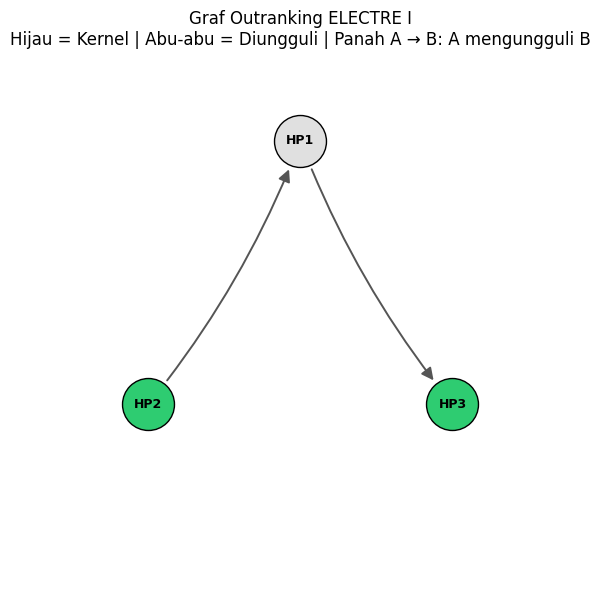

In [ ]:
# ================================================================
# TAHAP 14
# VISUALISASI GRAF OUTRANKING
# ================================================================

judul("TAHAP 14 - GRAF OUTRANKING ELECTRE I")

n = jumlah_alternatif
sudut = np.linspace(0, 2 * np.pi, n, endpoint=False) + np.pi / 2
posisi = np.column_stack([np.cos(sudut), np.sin(sudut)])

ukuran = max(6, min(12, 4 + n * 0.5))
fig, ax = plt.subplots(figsize=(ukuran, ukuran))

# Panah outranking
for i in range(n):
    for j in range(n):
        if matriks_agregat[i, j] == 1:
            panah = FancyArrowPatch(
                posisi[i],
                posisi[j],
                arrowstyle="-|>",
                mutation_scale=18,
                shrinkA=22,
                shrinkB=22,
                color="#555555",
                linewidth=1.4,
                connectionstyle="arc3,rad=0.08"
            )
            ax.add_patch(panah)

# Node
for i in range(n):
    if status_kernel[i].startswith("Kernel (alternatif"):
        warna_node = "#2ECC71"
    elif status_kernel[i] == "Kernel (sebagian)":
        warna_node = "#F1C40F"
    else:
        warna_node = "#E0E0E0"

    ax.scatter(
        posisi[i, 0],
        posisi[i, 1],
        s=1400,
        color=warna_node,
        edgecolor="black",
        zorder=3
    )

    ax.text(
        posisi[i, 0],
        posisi[i, 1],
        nama_alternatif[i],
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold",
        zorder=4
    )

ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(
    "Graf Outranking ELECTRE I\n"
    "Hijau = Kernel | Abu-abu = Diungguli | Panah A \u2192 B: A mengungguli B"
)

plt.tight_layout()
plt.show()

In [ ]:
# ================================================================
# TAHAP 15
# MENYIMPAN DAN MENGUNDUH HASIL
# ================================================================

judul("TAHAP 15 - MENYIMPAN HASIL")

nama_file_hasil = "hasil_perhitungan_electre_1.xlsx"

df_kernel = pd.DataFrame({
    "Kernel": [
        f"Kernel {nomor}" for nomor in range(1, len(daftar_kernel) + 1)
    ],
    "Anggota": [
        ", ".join(nama_alternatif[i] for i in kernel)
        for kernel in daftar_kernel
    ]
})

with pd.ExcelWriter(nama_file_hasil, engine="openpyxl") as writer:

    df.to_excel(writer, sheet_name="Data Awal", index=False)
    konfigurasi.to_excel(writer, sheet_name="Konfigurasi", index=False)
    tabel_penyebut.to_excel(writer, sheet_name="Penyebut Normalisasi", index=False)
    df_normalisasi.to_excel(writer, sheet_name="Normalisasi")
    df_terbobot.to_excel(writer, sheet_name="Matriks Terbobot")
    df_himpunan_c.to_excel(writer, sheet_name="Himpunan Concordance")
    df_himpunan_d.to_excel(writer, sheet_name="Himpunan Discordance")
    df_matriks_c.to_excel(writer, sheet_name="Matriks Concordance")
    df_matriks_d.to_excel(writer, sheet_name="Matriks Discordance")
    tabel_threshold.to_excel(writer, sheet_name="Threshold", index=False)
    df_dominan_c.to_excel(writer, sheet_name="Dominan Concordance")
    df_dominan_d.to_excel(writer, sheet_name="Dominan Discordance")
    df_agregat.to_excel(writer, sheet_name="Matriks Agregat")
    df_relasi.to_excel(writer, sheet_name="Relasi Outranking", index=False)
    df_kernel.to_excel(writer, sheet_name="Kernel", index=False)
    hasil_electre.to_excel(writer, sheet_name="Hasil ELECTRE I", index=False)

    # Merapikan setiap sheet
    workbook = writer.book

    for nama_sheet in workbook.sheetnames:
        worksheet = workbook[nama_sheet]
        worksheet.freeze_panes = "A2"

        for kumpulan_sel in worksheet.columns:
            panjang_maksimum = 0
            huruf_kolom = kumpulan_sel[0].column_letter

            for sel in kumpulan_sel:
                if sel.value is not None:
                    panjang_maksimum = max(
                        panjang_maksimum,
                        len(str(sel.value))
                    )

            worksheet.column_dimensions[huruf_kolom].width = min(
                panjang_maksimum + 2,
                45
            )

print(f"File berhasil dibuat: {nama_file_hasil}")

files.download(nama_file_hasil)